# 01 · Data understanding and preprocessing
Exploration of the VisDrone2019-VID subset used in the competition. Figures are saved to `images/` for the report. Preprocessing itself lives in `src/prepare_data.py`.

In [1]:
import sys, json, collections
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
sys.path.insert(0, str(Path.cwd().parent / 'src'))
from common import DATA, PREP, ROOT, CLASSES, read_yolo_boxes, flat_name
IMG = ROOT / 'images'; IMG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

## 1. Load annotations
COCO json carries per-frame `video` / `frame_id` and per-object `track_id`, `occlusion`; ignored regions are `iscrowd=1`.

In [2]:
def load(split):
    d = json.load(open(DATA / split / 'annotations_coco.json'))
    im = pd.DataFrame(d['images']).rename(columns={'id': 'image_id'})
    an = pd.DataFrame(d['annotations'])
    an = an.merge(im[['image_id', 'video', 'frame_id', 'width', 'height']], on='image_id')
    an['split'] = split
    im['split'] = split
    return im, an
im_tr, an_tr = load('train'); im_va, an_va = load('val')
ims, anns = pd.concat([im_tr, im_va], ignore_index=True), pd.concat([an_tr, an_va], ignore_index=True)
obj = anns[anns.iscrowd == 0].copy(); ign = anns[anns.iscrowd == 1].copy()
obj['cls'] = obj.category_id - 1
obj['w'] = obj.bbox.str[2]; obj['h'] = obj.bbox.str[3]
obj['size'] = np.sqrt(obj.w * obj.h)                      # sqrt(area), original pixels
obj['scale1024'] = 1024 / obj[['width', 'height']].max(axis=1)   # resize factor to 1024 long side
obj['size1024'] = obj['size'] * obj['scale1024']
print(f"train: {len(im_tr)} frames / {im_tr.video.nunique()} sequences, val: {len(im_va)} / {im_va.video.nunique()}")
print(f"objects: {len(obj):,}, ignored regions: {len(ign):,}")

train: 24201 frames / 56 sequences, val: 2846 / 7
objects: 1,219,648, ignored regions: 542,704


## 2. Sequences: resolution, length, density

In [3]:
seq = (obj.groupby(['split', 'video']).agg(objects=('id', 'size'), median_size=('size', 'median'))
       .join(ims.groupby(['split', 'video']).agg(frames=('image_id', 'size'), width=('width', 'first'),
                                                  height=('height', 'first'))))
seq['obj_per_frame'] = seq.objects / seq.frames
seq = seq.reset_index()
test = pd.read_csv(DATA / 'test_images.csv')
print('test:', test['clip'].nunique(), 'clips,', len(test), 'frames; frames per clip', test.groupby('clip').size().describe()[['min','50%','max']].tolist())
res = pd.concat([ims.assign(res=ims.width.astype(str) + 'x' + ims.height.astype(str))[['split', 'res']],
                 test.assign(split='test', res=test.width.astype(str) + 'x' + test.height.astype(str))[['split', 'res']]], ignore_index=True)
display(pd.crosstab(res.res, res.split))
seq.sort_values('obj_per_frame').round(1)

test: 48 clips, 3811 frames; frames per clip [35.0, 73.5, 148.0]


split,test,train,val
res,,,
1344x756,441,5645,827
1360x764,1474,0,0
1360x765,0,962,0
1904x1071,0,12895,459
1904x1072,305,0,0
1920x1080,991,721,0
2688x1512,0,3505,233
2720x1530,0,473,349
3840x2160,0,0,978


,split,video,objects,median_size,frames,width,height,obj_per_frame
19,train,uav0000218_00001_v,1158,62.1,225,2688,1512,5.1
29,train,uav0000266_04830_v,706,81.6,116,2688,1512,6.1
26,train,uav0000263_03289_v,4686,54.9,725,1904,1071,6.5
28,train,uav0000266_03598_v,3548,80.9,548,2688,1512,6.5
11,train,uav0000099_02109_v,8955,37.1,1255,1344,756,7.1
...,...,...,...,...,...,...,...,...
18,train,uav0000150_02310_v,37892,60.0,348,2688,1512,108.9
5,train,uav0000072_04488_v,9382,45.8,85,1904,1071,110.4
12,train,uav0000124_00944_v,49578,46.3,398,2688,1512,124.6
13,train,uav0000126_00001_v,54474,48.4,412,2688,1512,132.2


**Observation.** Validation is not distributed like test: one val sequence is 3840×2160 (≈1/3 of val frames), while test frames are at most 1920×1080. Sequence density varies by an order of magnitude, so per-sequence (not per-frame) splitting matters.

## 3. Class balance

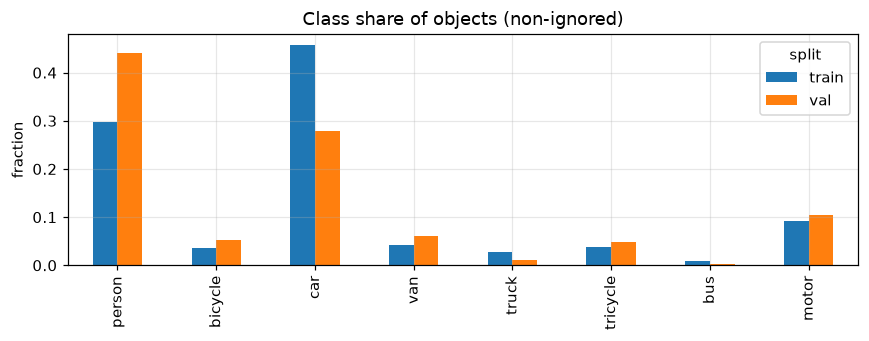

split,train,val,train_share
person,328701,50312,0.297
bicycle,40255,6022,0.036
car,505301,31821,0.457
van,46940,6842,0.042
truck,30498,1359,0.028
tricycle,41349,5487,0.037
bus,9653,264,0.009
motor,102819,12025,0.093


In [4]:
cnt = obj.groupby(['split', 'cls']).size().unstack(0).fillna(0)
cnt.index = CLASSES
frac = cnt / cnt.sum()
ax = frac.plot.bar(figsize=(8, 3.2), title='Class share of objects (non-ignored)')
ax.set_ylabel('fraction'); plt.tight_layout(); plt.savefig(IMG / 'eda_classes.png'); plt.show()
cnt.astype(int).assign(train_share=frac.train.round(3))

## 4. Object sizes
COCO thresholds: small < 32², medium < 96², large ≥ 96² (computed on ORIGINAL pixels in evaluation).

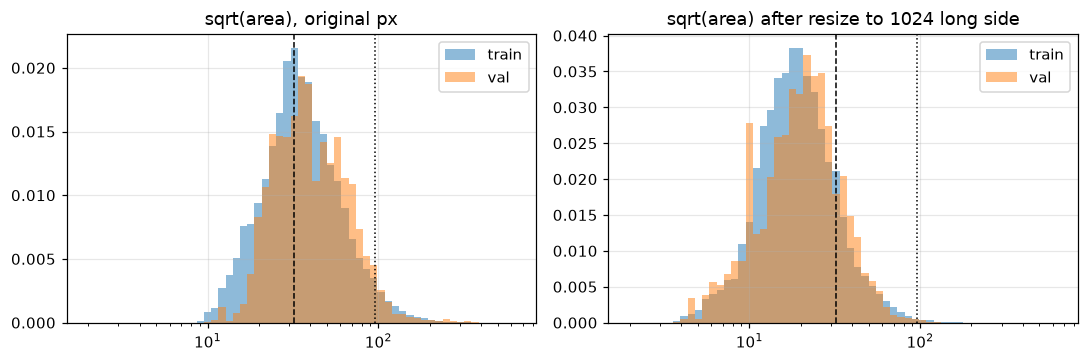

,p10,median,p90,small%,medium%
split,,,,,
train,24.0,45.8,101.6,24.9,63.5
val,26.1,52.4,99.3,19.2,69.5


,p10,median,p90,small%,medium%
split,,,,,
train,12.9,24.3,53.0,69.1,29.5
val,13.4,26.1,49.4,66.1,33.3


,"median size, px"
cls,
person,36.7
bicycle,43.9
car,57.5
van,51.3
truck,73.9
tricycle,54.5
bus,111.7
motor,39.8


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
bins = np.logspace(0.3, 2.8, 60)
for s, g in obj.groupby('split'):
    axs[0].hist(g['size'], bins, density=True, alpha=.5, label=s)
    axs[1].hist(g['size1024'], bins, density=True, alpha=.5, label=s)
for ax, t in zip(axs, ['sqrt(area), original px', 'sqrt(area) after resize to 1024 long side']):
    ax.set_xscale('log'); ax.axvline(32, c='k', ls='--', lw=1); ax.axvline(96, c='k', ls=':', lw=1); ax.set_title(t); ax.legend()
plt.tight_layout(); plt.savefig(IMG / 'eda_sizes.png'); plt.show()
q = lambda x: pd.Series({'p10': x.quantile(.1), 'median': x.median(), 'p90': x.quantile(.9),
                         'small%': (x < 32).mean() * 100, 'medium%': ((x >= 32) & (x < 96)).mean() * 100})
display(obj.groupby('split')['size'].apply(q).unstack().round(1))
display(obj.groupby('split')['size1024'].apply(q).unstack().round(1))
obj.groupby('cls')['size'].median().rename(index=dict(enumerate(CLASSES))).round(1).to_frame('median size, px')

**Observation.** At 1024 input the median object is ≈25 px and 10% are below ≈13 px, i.e. below one cell of a stride-16 feature map → motivates (i) higher input resolution, (ii) a stride-4 (P2) level / small anchors.

## 5. Objects per frame

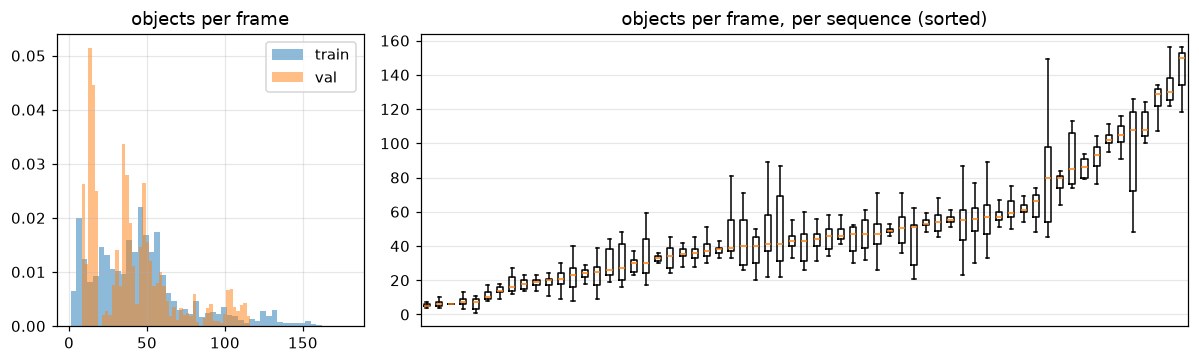

{'count': 27044.0, 'mean': 45.1, 'std': 31.1, 'min': 1.0, '50%': 42.0, '90%': 90.0, '99%': 140.0, 'max': 180.0}


In [6]:
opf = obj.groupby(['split', 'video', 'image_id']).size().rename('n').reset_index()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={'width_ratios': [1, 2.5]})
for s, g in opf.groupby('split'): axs[0].hist(g.n, 50, alpha=.5, density=True, label=s)
axs[0].set_title('objects per frame'); axs[0].legend()
order = opf.groupby('video').n.median().sort_values().index
axs[1].boxplot([opf[opf.video == v].n for v in order], showfliers=False)
axs[1].set_xticks([]); axs[1].set_title('objects per frame, per sequence (sorted)')
plt.tight_layout(); plt.savefig(IMG / 'eda_density.png'); plt.show()
print(opf.n.describe(percentiles=[.5, .9, .99]).round(1).to_dict())

**Observation.** Up to several hundred objects per frame → default `max_det=100` / 100 DETR queries is not enough; we use 500 detections per image (the Kaggle cap) and test 500 queries for RT-DETR.

## 6. Box shapes and anchor configuration (k-means with 1−IoU distance, YOLOv2)

In [7]:
def iou_wh(wh, c):
    inter = np.minimum(wh[:, None, 0], c[None, :, 0]) * np.minimum(wh[:, None, 1], c[None, :, 1])
    return inter / (wh[:, None].prod(-1) + c[None].prod(-1) - inter)
def kmeans_iou(wh, k, it=50, seed=0):
    rng = np.random.default_rng(seed); c = wh[rng.choice(len(wh), k, replace=False)]
    for _ in range(it):
        a = iou_wh(wh, c).argmax(1)
        c = np.array([np.median(wh[a == j], 0) if (a == j).any() else c[j] for j in range(k)])
    return c[np.argsort(c.prod(1))], iou_wh(wh, c).max(1).mean()
tr = obj[obj.split == 'train'].sample(100_000, random_state=0)
wh = (tr[['w', 'h']].values * tr.scale1024.values[:, None]).astype(float)
for k in (5, 9):
    c, miou = kmeans_iou(wh, k); print(f'k={k}: mean best IoU {miou:.3f}; anchors (w,h)@1024:', np.round(c, 1).tolist())
ar = np.log2(tr.h / tr.w)
print('aspect h/w quantiles:', np.round(2 ** ar.quantile([.1, .5, .9]).values, 2))
default = np.array([[s * np.sqrt(1 / r), s * np.sqrt(r)] for s in (32, 64, 128, 256, 512) for r in (.5, 1, 2)])
small = np.array([[s * np.sqrt(1 / r), s * np.sqrt(r)] for s in (16, 32, 64, 128, 256) for r in (.5, 1, 2)])
for n, A in [('torchvision default 32-512', default), ('small 16-256', small)]:
    best = iou_wh(wh, A).max(1)
    print(f'{n:28s} mean best IoU {best.mean():.3f}; GT with best IoU<0.5 (no positive anchor at 0.5 thr): {(best < .5).mean():.1%}')

k=5: mean best IoU 0.660; anchors (w,h)@1024: [[10.1, 13.0], [15.6, 23.7], [33.9, 21.5], [25.9, 38.2], [67.4, 49.5]]


k=9: mean best IoU 0.729; anchors (w,h)@1024: [[8.6, 12.4], [11.3, 22.6], [17.5, 15.1], [16.7, 32.3], [23.7, 24.4], [33.5, 18.3], [31.7, 42.5], [51.6, 28.0], [81.2, 58.7]]
aspect h/w quantiles: [0.47 1.06 2.25]
torchvision default 32-512   mean best IoU 0.510; GT with best IoU<0.5 (no positive anchor at 0.5 thr): 44.8%
small 16-256                 mean best IoU 0.680; GT with best IoU<0.5 (no positive anchor at 0.5 thr): 6.1%


**Observation.** With torchvision's default anchors a large fraction of GT boxes have no anchor with IoU ≥ 0.5, i.e. they are never assigned as positives in RPN / RetinaNet. Shifting the anchor pyramid down by one octave (16–256) fixes most of them → used in the tuned anchor-based models.

## 7. Ignored regions

In [8]:
ign['area_frac'] = ign.area / (ign.width * ign.height)
per_img = ign.groupby(['split', 'image_id']).area_frac.sum().clip(upper=1)
frames_with = per_img.groupby('split').size() / ims.groupby('split').size()
print('frames with ignored regions:', frames_with.round(3).to_dict())
print('mean ignored area fraction (frames that have them):', per_img.groupby('split').mean().round(3).to_dict())

frames with ignored regions: {'train': 0.747, 'val': 0.504}
mean ignored area fraction (frames that have them): {'train': 0.236, 'val': 0.256}


## 8. Temporal redundancy → frame subsampling step
IoU of the same `track_id` between frame t and t+k: high IoU means the frame adds little new information.

In [9]:
t = obj[obj.split == 'train'][['video', 'track_id', 'frame_id', 'bbox']].copy()
t[['x', 'y', 'w', 'h']] = np.stack(t.bbox.values)
t = t.set_index(['video', 'track_id', 'frame_id'])[['x', 'y', 'w', 'h']]
def box_iou(a, b):
    x1 = np.maximum(a.x, b.x); y1 = np.maximum(a.y, b.y)
    x2 = np.minimum(a.x + a.w, b.x + b.w); y2 = np.minimum(a.y + a.h, b.y + b.h)
    inter = (x2 - x1).clip(0) * (y2 - y1).clip(0)
    return inter / (a.w * a.h + b.w * b.h - inter)
rows = []
base = t.sample(200_000, random_state=0)
for k in (1, 2, 5, 10, 20, 40):
    nxt = base.rename(lambda f: f + k, level=2)
    j = nxt.join(t, how='inner', lsuffix='_a')
    a = j[['x_a', 'y_a', 'w_a', 'h_a']].set_axis(['x', 'y', 'w', 'h'], axis=1)
    rows.append({'step k': k, 'same-track IoU (median)': box_iou(a, j[['x', 'y', 'w', 'h']]).median(),
                 'track survives': len(j) / len(base)})
pd.DataFrame(rows).round(3)

,step k,same-track IoU (median),track survives
0,1,0.897,0.993
1,2,0.810,0.986
2,5,0.598,0.966
3,10,0.358,0.933
4,20,0.104,0.870
5,40,0.000,0.757


**Choice.** Consecutive frames are near-duplicates. For the model comparison we train on every 10th frame (2,446 frames, ~110k boxes) so each run fits a ~1 h budget on one 8 GB GPU; validation uses every 5th val frame (571 frames, all 7 sequences). The final model uses a denser step.

## 9. Verifying the conversion: GT boxes on raw frames and on the prepared (masked) training images

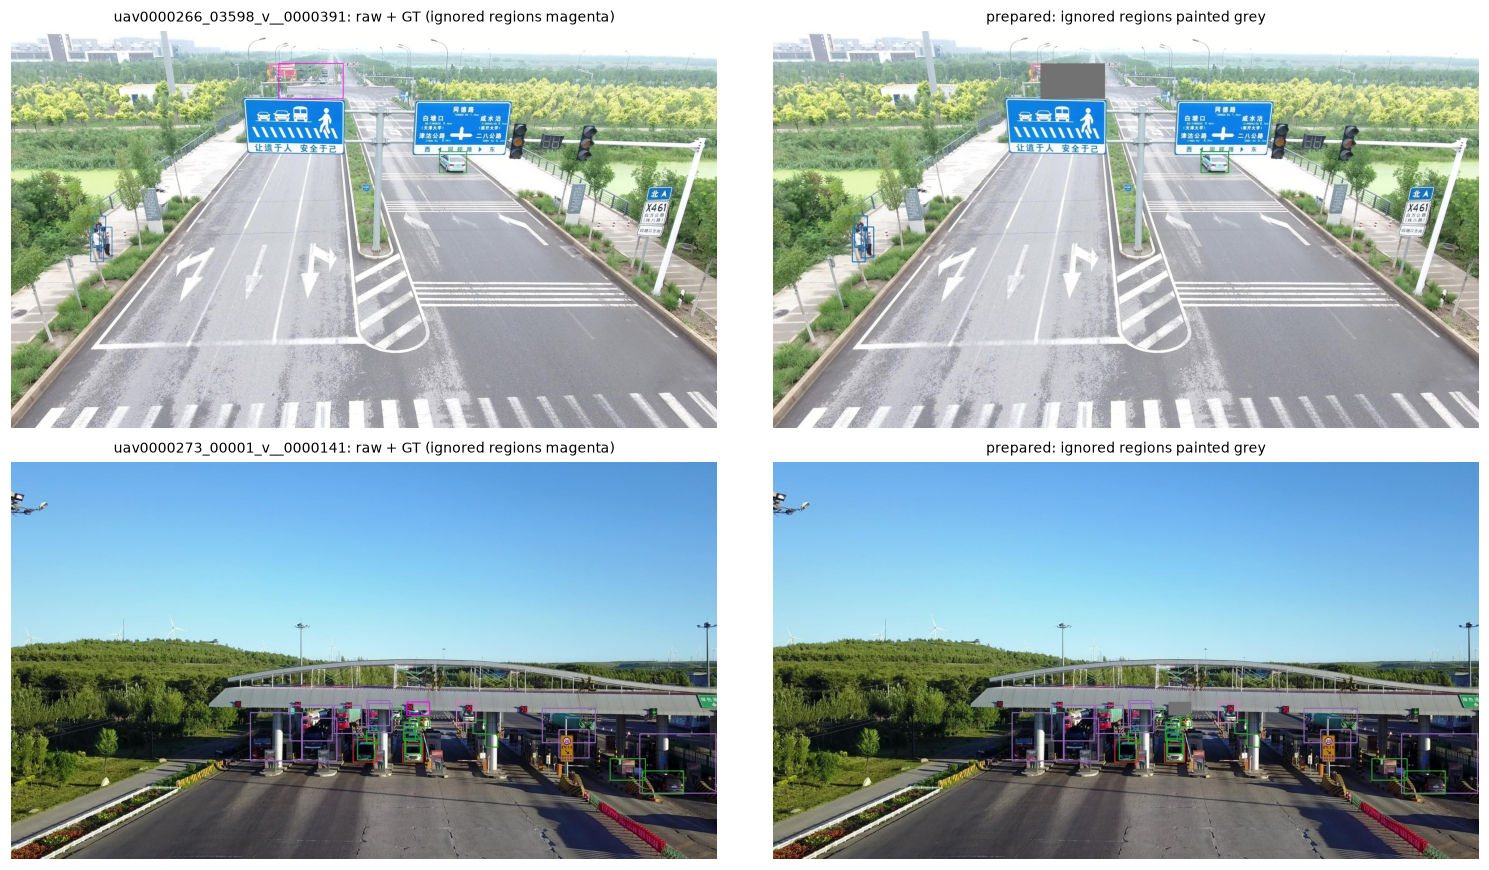

In [10]:
rng = np.random.default_rng(1)
colors = plt.cm.tab10(np.arange(8))[:, :3] * 255
def draw(img, boxes_xyxy, cls, ign_xyxy=()):
    img = img.copy()
    for x1, y1, x2, y2 in ign_xyxy: cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 255), 2)
    for (x1, y1, x2, y2), c in zip(boxes_xyxy, cls): cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), colors[int(c)].tolist(), 2)
    return img
stems = sorted(p.stem for p in (PREP / 'train_s10' / 'images').glob('*.jpg'))
has_ign = [s for s in stems if (DATA / 'train' / 'ignore' / s.split('__')[0] / (s.split('__')[1] + '.txt')).exists()]
fig, axs = plt.subplots(2, 2, figsize=(14, 8))
for row, s in zip(axs, rng.choice(has_ign, 2, replace=False)):
    v, f = s.split('__')
    raw = cv2.cvtColor(cv2.imread(str(DATA / 'train' / 'images' / v / f'{f}.jpg')), cv2.COLOR_BGR2RGB)
    prep = cv2.cvtColor(cv2.imread(str(PREP / 'train_s10' / 'images' / f'{s}.jpg')), cv2.COLOR_BGR2RGB)
    for ax, img, lab_path in [(row[0], raw, DATA / 'train' / 'labels' / v / f'{f}.txt'),
                              (row[1], prep, PREP / 'train_s10' / 'labels' / f'{s}.txt')]:
        H, W = img.shape[:2]
        L = read_yolo_boxes(lab_path); I = read_yolo_boxes(DATA / 'train' / 'ignore' / v / f'{f}.txt', has_class=False)
        xyxy = lambda b: np.stack([(b[:, 0] - b[:, 2] / 2) * W, (b[:, 1] - b[:, 3] / 2) * H, (b[:, 0] + b[:, 2] / 2) * W, (b[:, 1] + b[:, 3] / 2) * H], 1)
        ax.imshow(draw(img, xyxy(L[:, 1:]), L[:, 0], xyxy(I) if ax is row[0] else ()))
        ax.set_axis_off()
    row[0].set_title(f'{s}: raw + GT (ignored regions magenta)', fontsize=9); row[1].set_title('prepared: ignored regions painted grey', fontsize=9)
plt.tight_layout(); plt.savefig(IMG / 'eda_gt_check.png', dpi=80); plt.show()